## Core 807 Diagenesis Notebook

In [ ]:
## install dependencies 
%pip install numpy; pandas; matplotlib; scipy; numba; corner; emcee; torch; gpytorch; h5py

Note: you may need to restart the kernel to use updated packages.


In [2]:
#import packages and functions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

from plotter import plot_d18O, plot_d18O_expR, plot_D47, plot_T_clump, plot_R, plot_D47_expR, plot_R_expR
from data_and_boundary_conditions import import_data_and_make_boundary_conditions, plot_single_gp_fit
from MCMC_fit_d18O import MLE_full_core, MLE_top_core, diag_MCMC, neg_log_likelihood_d18O_4top_4data_mean, neg_log_likelihood_d18O_4data_mean, log_probability_d18O_4top_4data, log_probability_d18O_4data, _log_likelihood_d18O_batch, _log_likelihood_d18O_4top_batch
from MCMC_fit_D47 import neg_log_likelihood_D47_4top_4data_mean, neg_log_likelihood_D47_4data_mean, log_probability_D47_4top_4data, log_probability_D47_4data, _log_likelihood_D47_4top_batch, _log_likelihood_D47_batch
from lik_variance import diagnose_lik_variance
from percentile_plotter import percentiles

The following cell will download .h5 files from Zenodo (https://zenodo.org/records/24322863) corresponding to Markov Chains run for this analysis. If you would like to add to/work with the Markov Chains, the run the cell below. If you would like to run your own Markov chain, feel free to skip.

In [3]:
# download chains from zenodo
%run download_chains.py


  100.0%  (682 / 682 MB)
  100.0%  (356 / 356 MB)
  100.0%  (478 / 478 MB)
  100.0%  (423 / 423 MB)

Done.


# Setting boundary conditions and data

Before running and of the scripts in this notebook, all of the data and boundary condition relationships need to be set within the excel sheet "data_and_boundary_conditions.xlsx". If you want to change age-depth, SST-time, Deep_T-time, all of that should be done in the excel sheet. Everything will update automatically. All the paths are relative, so this should work on any computer.

# Import data and make boundary condition models

Once the "data_and_boundary_conditions" excel sheet is filled in, we can import the data.
> import_data_and_make_boundary_conditions

This function takes no arguments and imports the data. The function makes a Gaussian process (GP) model for SST-TEX86 and benthic $\delta^{18}\text{O}$, loads in Rohling 2024 seawater $\delta^{18}\text{O}$, and calculates deep ocean temperature. GP models for the measured 807 $\delta^{18}\text{O}$ and $\Delta_{47}$ are also calculated.

After running, it is set up as a class and has functions to save or load the boundary condition models from a saved file.

In [3]:
# option to load models for boundary conditions and data from a save file
boundary_conditions_and_data = import_data_and_make_boundary_conditions.load_boundary_conditions(filepath= './boundary_conditions_and_data_model.pt')

Loaded boundary condition distributions from ./boundary_conditions_and_data_model.pt


In [ ]:
# if not loading boundary conditions, then run this cell to import data and make the models

# h (in millions of years) determines the the resolution at which the model runs
h = 1 #Myr

# t_switch (in millions of years) set the boundary between the top and bottom part of the core. 
t_switch = 30 #Myr

# import the data and set the boundary conditions according to the resoltion and t_switch we specify
boundary_conditions_and_data = import_data_and_make_boundary_conditions(t_switch, h) ## will take a while

Imported: data_and_boundary_conditions - SST History
Imported: data_and_boundary_conditions - SST data
Imported: data_and_boundary_conditions - deep-ocean T history
Imported: data_and_boundary_conditions - Benthic Foram d18O
Imported: data_and_boundary_conditions - seawater 18O history
Imported: data_and_boundary_conditions - seawater 18O
Imported: data_and_boundary_conditions - depth-age
Imported: data_and_boundary_conditions - d18O Turner data
Imported: data_and_boundary_conditions - d18O Stolper 2018 data
Imported: data_and_boundary_conditions - D47 Turner data
Imported: data_and_boundary_conditions - D47 Stolper 2018 data
Imported: leg130and192data - 1187
Imported: leg130and192data - 1186
Imported: leg130and192data - 1185
Imported: leg130and192data - 1184
Imported: leg130and192data - 1183
Imported: leg130and192data - 807
Imported: leg130and192data - 806
Imported: leg130and192data - 805
Imported: leg130and192data - 804
Imported: leg130and192data - 803
Imported: leg130and192data - U1

In [4]:
# option to save models for boundary conditions and data to a save file
boundary_conditions_and_data.save_boundary_conditions(filepath= './boundary_conditions_and_data_model.pt')

Saved boundary condition distributions to ./boundary_conditions_and_data_model.pt


Plot and view the $\delta^{18}\text{O}$ and $\Delta_{47}$ data, as well as the GP models.

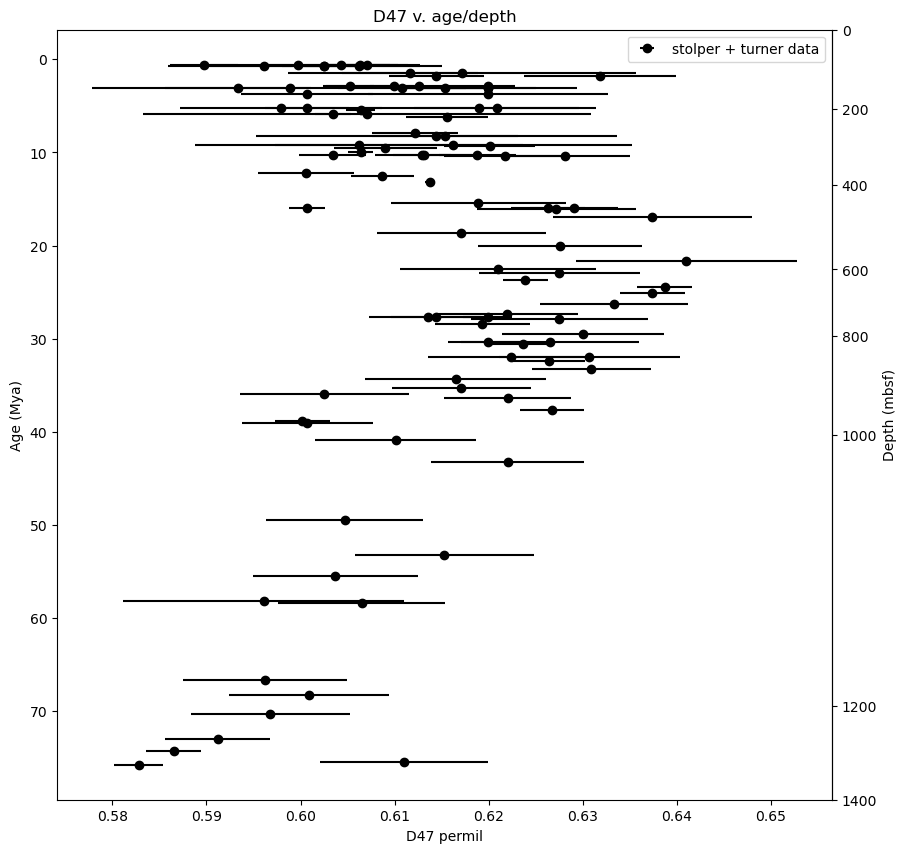

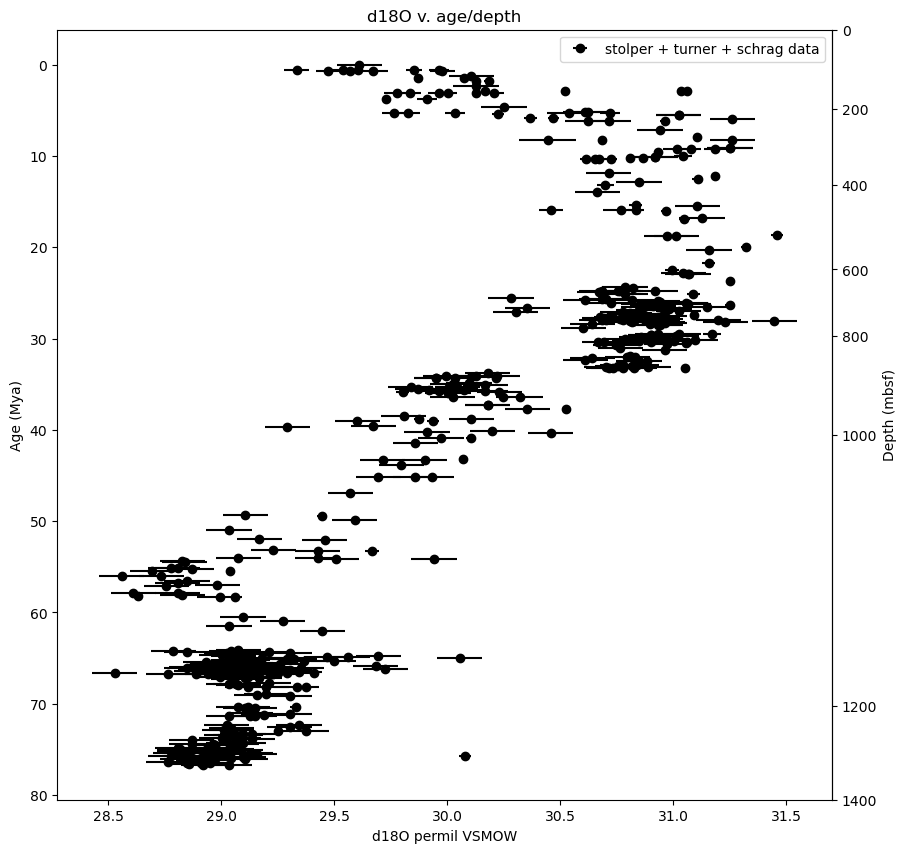

In [3]:
# plot data alone
plot_D47(boundary_conditions_and_data= boundary_conditions_and_data)
plot_d18O(boundary_conditions_and_data= boundary_conditions_and_data)

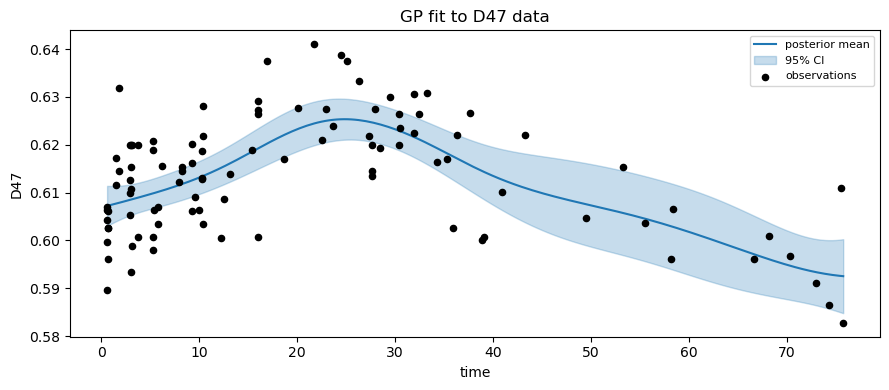

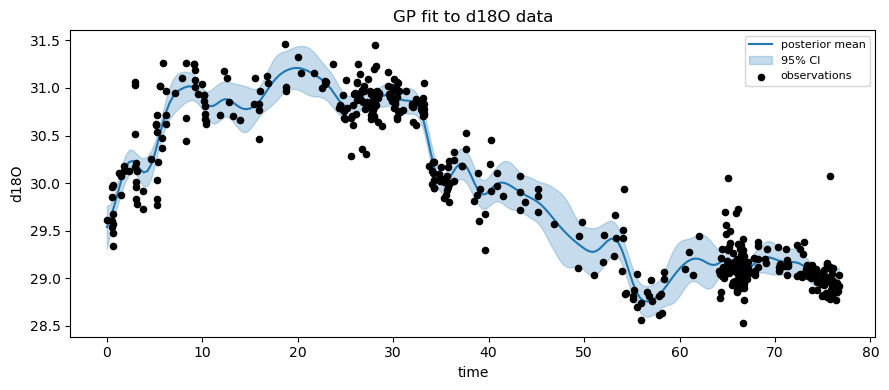

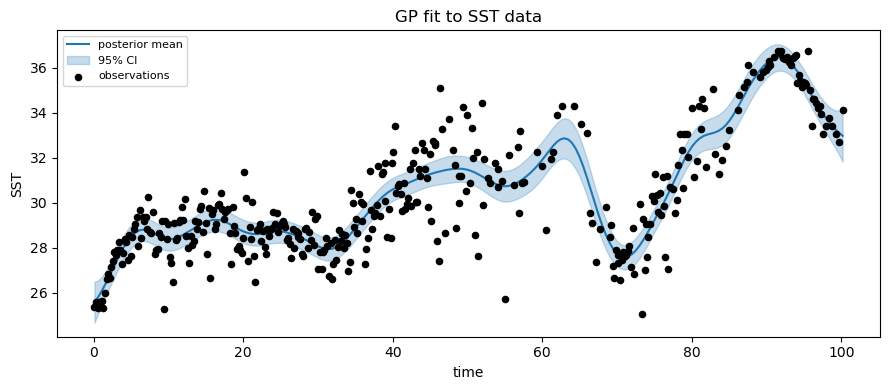

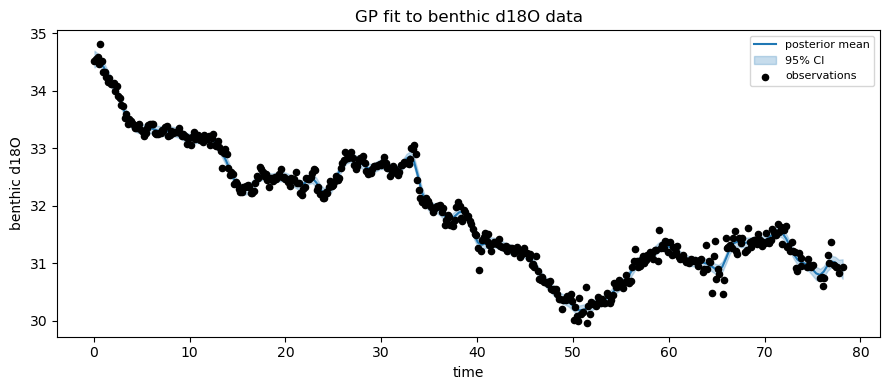

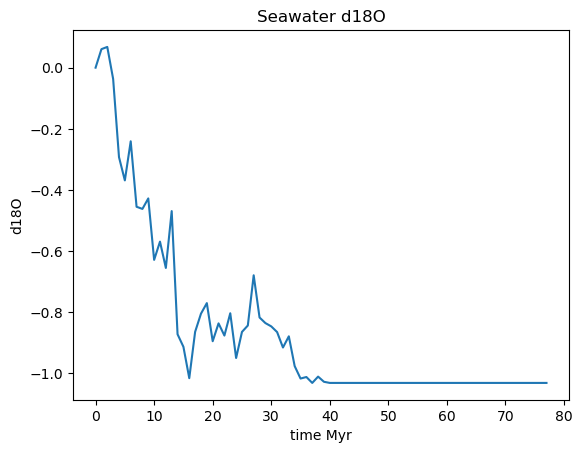

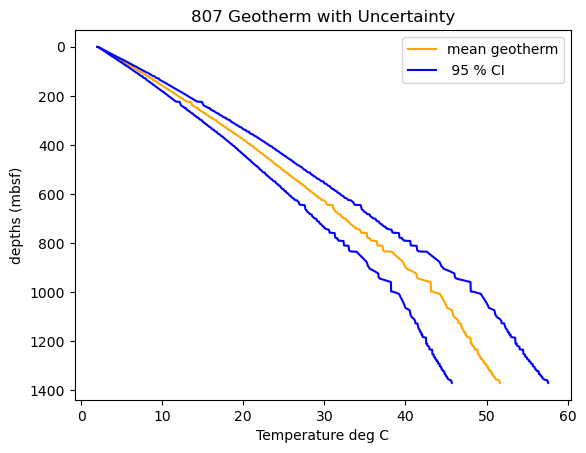

In [4]:
fig0, axes0 = plot_single_gp_fit(boundary_conditions_and_data.modelD47, boundary_conditions_and_data.likelihoodD47, boundary_conditions_and_data.tspace_data, boundary_conditions_and_data.D47, boundary_conditions_and_data.tspace_data.mean(), boundary_conditions_and_data.tspace_data.std(), boundary_conditions_and_data.D47_mean, boundary_conditions_and_data.D47_std, name="D47", n_query=200, include_obs_noise=False)
fig1, axes1 = plot_single_gp_fit(boundary_conditions_and_data.modeld18O, boundary_conditions_and_data.likelihoodd18O, boundary_conditions_and_data.tspace_data_d18O, boundary_conditions_and_data.d18O, boundary_conditions_and_data.tspace_data_d18O.mean(), boundary_conditions_and_data.tspace_data_d18O.std(), boundary_conditions_and_data.d18O_mean, boundary_conditions_and_data.d18O_std, name="d18O", n_query=200, include_obs_noise=False)

fig2, axes2 = plot_single_gp_fit(boundary_conditions_and_data.modelSST, boundary_conditions_and_data.likelihoodSST, boundary_conditions_and_data.SSTH_time, boundary_conditions_and_data.SSTH_data, boundary_conditions_and_data.SSTH_time.mean(), boundary_conditions_and_data.SSTH_time.std(), boundary_conditions_and_data.SSTH_data_mean, boundary_conditions_and_data.SSTH_data_std, name="SST", n_query=200, include_obs_noise=False)
fig3, axes3 = plot_single_gp_fit(boundary_conditions_and_data.model_benthic, boundary_conditions_and_data.likelihood_benthic, boundary_conditions_and_data.benthic_time, boundary_conditions_and_data.benthic_d18O_data, boundary_conditions_and_data.benthic_time.mean(), boundary_conditions_and_data.benthic_time.std(), boundary_conditions_and_data.benthic_d18O_mean, boundary_conditions_and_data.benthic_d18O_std, name="benthic d18O", n_query=200, include_obs_noise=False)

plt.figure()
plt.plot(boundary_conditions_and_data.coarse_time, boundary_conditions_and_data.seawater_coarse)
plt.xlabel('time Myr')
plt.ylabel('d18O')
plt.title('Seawater d18O')
plt.show()


plt.figure()
plt.plot(boundary_conditions_and_data.geotherm_mean, boundary_conditions_and_data.geotherm_depths, color = 'orange', label = 'mean geotherm')
plt.plot(boundary_conditions_and_data.geotherm_lower_95, boundary_conditions_and_data.geotherm_depths, color = 'blue', label = ' 95 % CI ')
plt.plot(boundary_conditions_and_data.geotherm_upper_95, boundary_conditions_and_data.geotherm_depths, color = 'blue',)
plt.gca().invert_yaxis()
plt.ylabel('depths (mbsf)')
plt.xlabel('Temperature deg C')
plt.title("807 Geotherm with Uncertainty")
plt.legend()
plt.show()

We can test to make sure our boundary condition function is working correctly by running `.draw_all_BCs_batch`

In [ ]:
rng = np.random.default_rng()
(tspace1, tspace2, T_deep1_all, T_deep2_all, depth1, depth2, SST_basis, SST_mean_norm, SSTH_data_mean, SSTH_data_std, seawater_d18O1_all, seawater_d18O2_all, geotherm1_all, geotherm2_all, indicies) = boundary_conditions_and_data.draw_all_BCs_batch(10, rng)
print(len(SST_basis))

Our goal is to perform model inversion using our diagenesis forward models. The diagenesis models require SST, seawater $\delta^{18}\text{O}$, deep ocean temperature (calculated from $\delta^{18}\text{O}$ of forams and seawater), a geothermal gradient, and recrystallization parameters. Our setup will invert for the recrystallization parameters and Karhunen-Loeve coefficents for SST, and use a pseudo-marginal approach to account for uncertainty in the geotherm and the $\delta^{18}\text{O}$ of forams. First, we need to check that the pseudo-marginal approach will work by checking the variance of the log-likelihood function evaulated at a reasonable choice of recrystallization parameters and SST.

TLDR: Quick check for probability functions. We want to ensure that our pseudo-MCMC approach has the right number of boundary condition draws per propoased theta. The rule of thumb is to have $\text{Var}(\text{log likelihood}(\theta)) \approx 1$

To get reasonable estimates of recrystallization parameters, we will use the maximum likelihood estimate (MLE) evaluated at the mean curves for each boundary condition.

In [6]:
theta_MLE_top_d18O = MLE_top_core(neg_log_likelihood_d18O_4top_4data_mean, boundary_conditions_and_data)
print('top core d18O:')
diagnose_lik_variance(theta_MLE_top_d18O, boundary_conditions_and_data, full_core = False, data_type = 'd18O', n_draws=30)

theta_MLE_full_d18O = MLE_full_core(neg_log_likelihood_d18O_4data_mean, boundary_conditions_and_data)
print('full core d18O:')
diagnose_lik_variance(theta_MLE_full_d18O, boundary_conditions_and_data, full_core = True, data_type = 'd18O', n_draws=30)

theta_MLE_top_D47 = MLE_top_core(neg_log_likelihood_D47_4top_4data_mean, boundary_conditions_and_data)
print('top core D47:')
diagnose_lik_variance(theta_MLE_top_D47, boundary_conditions_and_data, full_core = False, data_type = 'D47', n_draws=5)

theta_MLE_full_D47 = MLE_full_core(neg_log_likelihood_D47_4data_mean, boundary_conditions_and_data)
print('full core D47:')
diagnose_lik_variance(theta_MLE_full_D47, boundary_conditions_and_data, full_core = True, data_type = 'D47', n_draws=5)

top core d18O:
Var(log p_hat(D|theta)) 0.03372597810563897
full core d18O:
Var(log p_hat(D|theta)) 0.9652862421907216
top core D47:
Var(log p_hat(D|theta)) 0.012054860483013737
full core D47:
Var(log p_hat(D|theta)) 0.22014131367612752


We see $\text{Var}(\text{log likelihood}(\theta)) \approx \text{ or } < 1$ for `n_draws = 30, 5`, so we are in good shape to proceed.

# MCMC for $\delta^{18}\text{O}$

Maximum Likelihood Estimation (MLE) is a way to estimate model paramaters by optimizing a likelihood function. We will use MLE estimates to initialize our Markov Chain Monte Carlo (MCMC) run because our chain will converge faster if you start guessing and checking in an already "good" region  of the paramter space.

The goal of our model fitting exercise is to evaluate how resonable it is for "extra" pressure dissolution driven recrystallization to occur in a carbonate sediment starting around the chalk to limestone transition. First, we will fit out diagenesis model without extra recrystallization to the top section of the sediment core (ooze and chalk), then we will fit out model with extra recrystallation to the whole core. The difference between the two fits will illustrate whether or not adding extra recrystallization improves our fits.

## Top core fitting

To fit the top part of the sediment core, we will only fit to data before t_switch and we will paramaterize recrystallization as:
$$R(t) = \beta e^{-t/\gamma}$$

Because recrystallization is decaying exponentially, deeper parts of the core will experience effectively no recrystallition at depth. We suspect that our model here will not match the data well at depth because of this.

We will first calculate a MLE fit, then use the MLE fit to start out Markov Chain.

### MLE Top core fit

The MLE_top_core function has arguments:

>MLE_top_core(NLL_function, boundary_conditions_and_data, plot = False, initial_guess = init_guess)

The negative log-likelihood function (NLL_function) needs to be specifically for the top core:

`neg_log_likelihood_d18O_4top_4data_mean`

The `plot` option will display the MLE fits over the data. The `initial_guess` argument should only be changed from the default value of the optimization diverges.


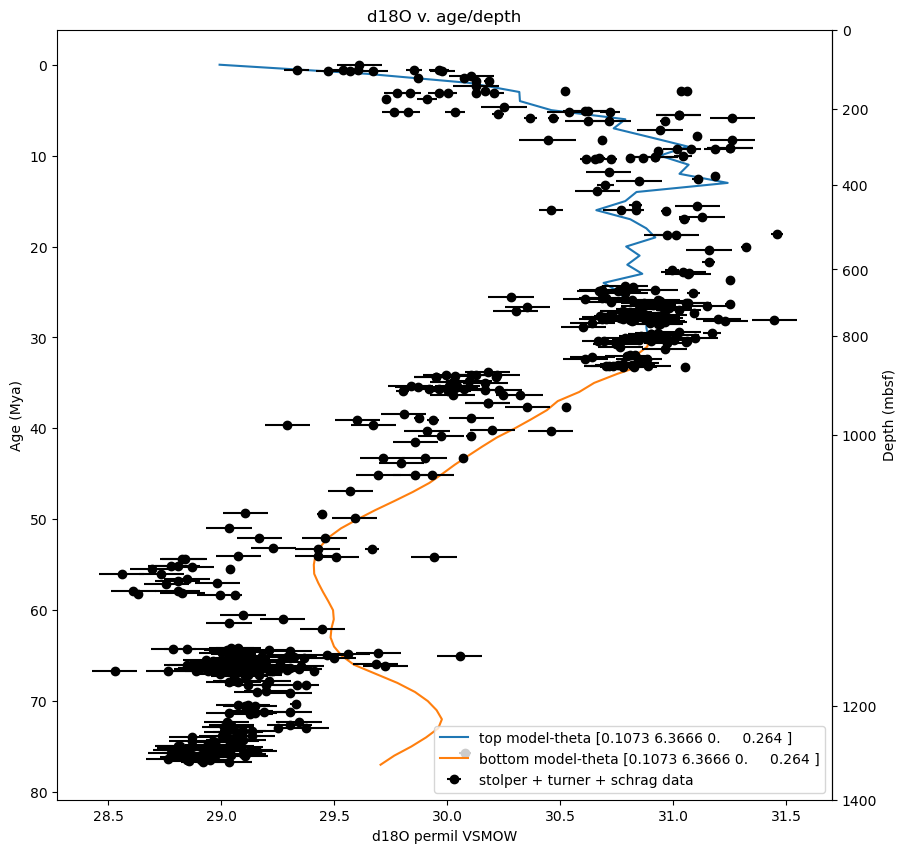

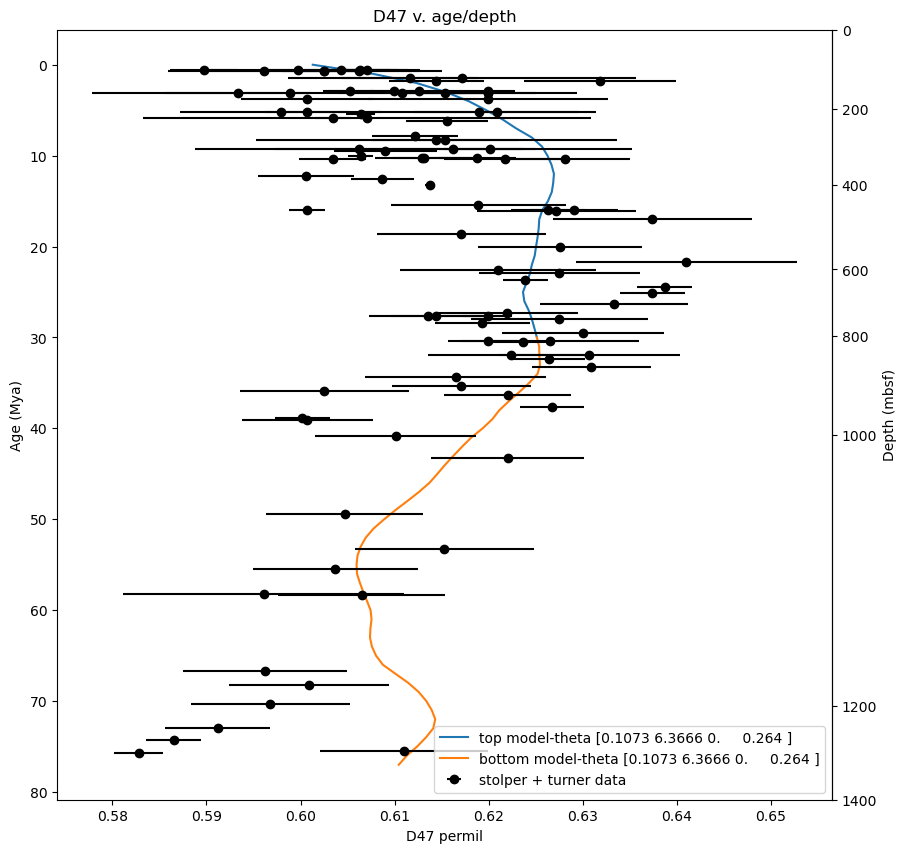

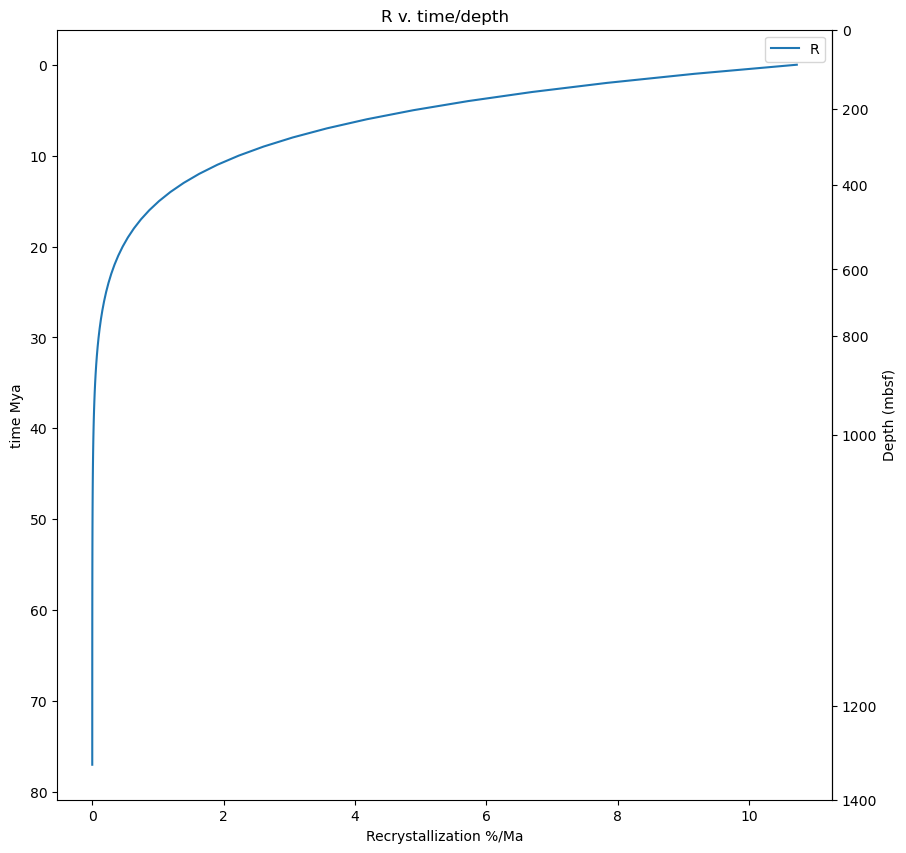

Integrated R top:  0.6768641388198519
theta_MLE =  [0.10727961 6.36655314 0.         0.26396521]
[beta, gamma, alpha,  s]


In [5]:
theta_MLE_top = MLE_top_core(neg_log_likelihood_d18O_4top_4data_mean, boundary_conditions_and_data, plot=True)
print('theta_MLE = ', theta_MLE_top)
print('[beta, gamma, alpha,', " s]")
theta_MLE_top =  np.append(theta_MLE_top, np.random.rand(len(SST_basis[1]))) # we optimize using the mean TEX86 SST, but append variables the will become the fit SST coefficients

### MCMC Top core fit

With the MLE fit in hand, we will start the MCMC fitting. The MCMC class has the arguments:

>diag_MCMC(walkers, nsteps, burnin, log_prob_fn, boundary_conditions_and_data, MLE_estimate, path = './', use_backend = None)

The number of `walkers` determines how many different Markov chains run in parallel and should be at least twice the number of paramaters you want to fit. The arguments `nsteps` and `burnin` tell the program how many guesses the program should make and how many of the guesses starting from the beginning to discard. You want to have a high enough `nsteps` to get your chain to converge and set `burnin` to be big enough to "forget" you initial conditions.

Similar to above, the `log_prob_fn` argument tells the function which probability function to use. The option for `log_prob_fn` when fitting the top core is:
 `log_probability_d18O_4top_4data`

The `path` argument tell the function where to save plots generated by the function. The two plots generated are a plot of the chains and a corner plot. The default path is the working directory folder, but here we will point the path to a specific folder for the top core.

The `use_backend` tells the emcee software to look for a previous MCMC run to resume. If `None` is used, then it will automatically make a new chain and overwrite any old chains. Turn `use_backend = True` if you run did not converge and you want to run for longer. If you can want to adjust the `burnin` length, you can run one or two more steps and adjust the the burnin length then.


100%|██████████| 2/2 [00:00<00:00,  3.11it/s]


Autocorrelation time: [ 86.44666629  88.61019856 253.82036095  79.76446548  74.52574556
  73.53249896  75.55845642  70.66944691  71.85218521  79.19403825
  72.74452536  79.44824861  81.49527786  75.81124135  79.52878352
  76.4936091   79.34527022  75.62096396  75.5151958 ]


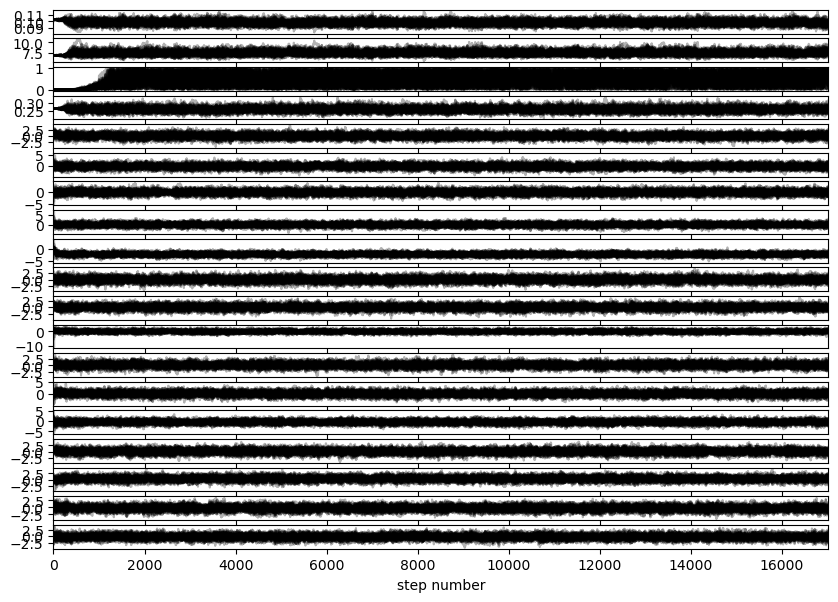

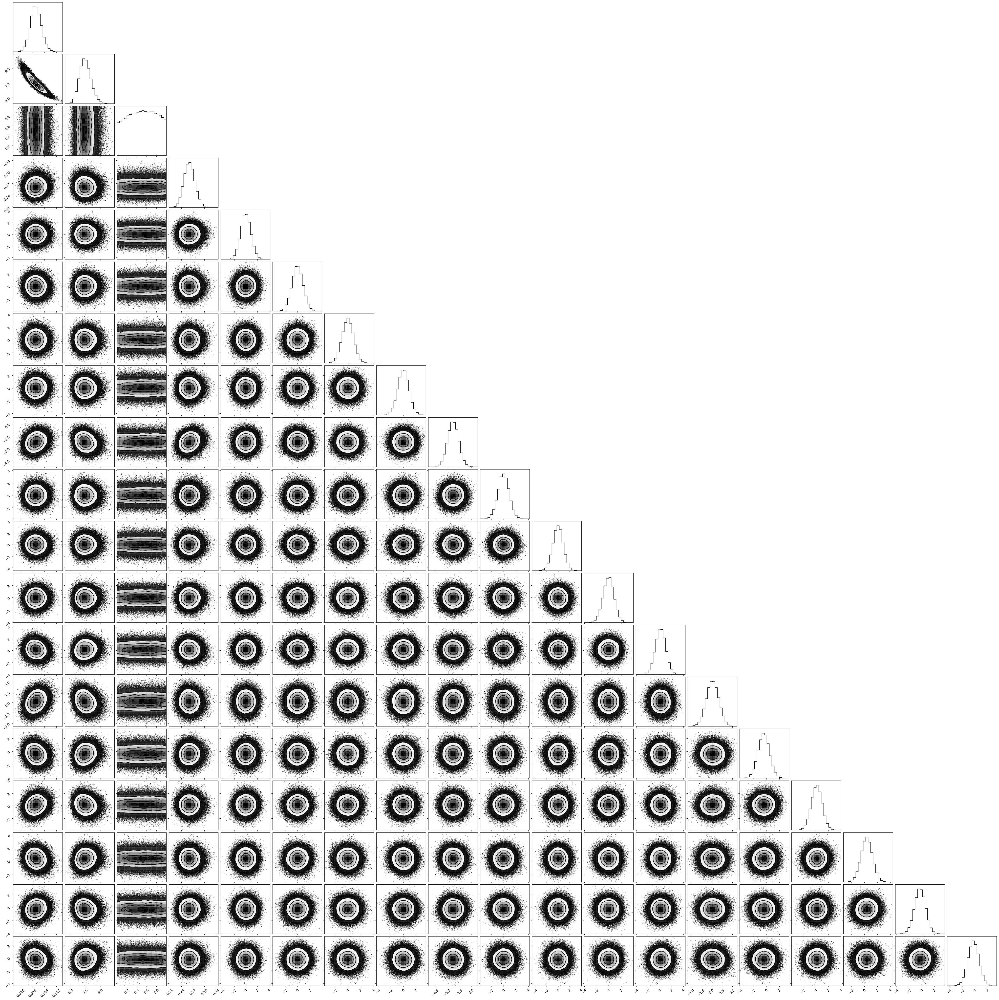

In [6]:
walkers = 40
n_steps = 2
burnin = 2000
MCMC_output_top = diag_MCMC(walkers, n_steps, burnin, log_probability_d18O_4top_4data, boundary_conditions_and_data, theta_MLE_top, path = './d18O_top/', use_backend=True)


In [7]:
print('fit theta: \n', MCMC_output_top.params)

fit theta: 
 [ 9.81604291e-02  7.43538138e+00  5.13017514e-01  2.61038449e-01
  8.90888667e-03  5.35228929e-03  2.57515109e-03  1.40633394e-02
 -2.23242187e+00 -1.20735585e-03  1.91544298e-03 -5.21502312e-02
  1.56402080e-01  1.49998853e-01 -3.75102594e-01  1.75663052e-01
  3.67576468e-01 -2.51402372e-01 -2.26356576e-01]


In [8]:
MCMC_output_top.sampler.acceptance_fraction

array([0.22215695, 0.22362547, 0.22867716, 0.22021852, 0.22297932,
       0.22362547, 0.22761983, 0.22597509, 0.22239192, 0.22368421,
       0.22421288, 0.21863252, 0.22714991, 0.22074718, 0.22767857,
       0.22679746, 0.22286184, 0.22156955, 0.22339051, 0.2243891 ,
       0.22004229, 0.22744361, 0.22421288, 0.21992481, 0.22879464,
       0.22051222, 0.22245066, 0.22456532, 0.22268562, 0.22151081,
       0.22297932, 0.22750235, 0.22562265, 0.21269972, 0.21651786,
       0.21692904, 0.22327303, 0.22650376, 0.2228031 , 0.22344925])

The `diag_MCMC` class has the following instance variables:


>self.flat_samples

^The Markov chain with the burnin discarded

>self.params

^theta, The meadian paramter estimates

>self.tau

^The autocorrelation time



**Pay attention to the autocorrelation times `tau`!** The autocorrelation time tells you after how many steps do you forget where you are in the paramter space. You get the effective sample size by dividing $N_{steps}/\tau$ for a given parameter. Generally, you want $\tau < N_{steps}/50$, which would be an effective sample size of 50 or greater for that given parameter. 

In [9]:
print('tau: ', MCMC_output_top.tau)

tau:  [ 86.44666629  88.61019856 253.82036095  79.76446548  74.52574556
  73.53249896  75.55845642  70.66944691  71.85218521  79.19403825
  72.74452536  79.44824861  81.49527786  75.81124135  79.52878352
  76.4936091   79.34527022  75.62096396  75.5151958 ]


### Plotting uncertainty percentiles

The `percentiles` class takes many arguments, but most of the are optional. 

The required arguments are `chain` and `tau`. The function will sample the chain at the "effective sample size" ($\max(\tau)/N_{steps}$), run the model for each sample, the plot the outputs as percentiles. It is important to input the flat samples from the `diag_MCMC` class as to not include the burnin. If you want to, you can add in any of the regression arguments to make the plots also overlay LOESS regression. The `full_core` argument tells the function whether or not you fit the the top or full core, and therefore what recrystallization model to use. The `path` argument tells the function where to save the plots. It will also save multiple .csv files for the percentiles.

> percentiles(
        flat_samples,
        boundary_conditions_and_data,
        n_curves=500,
        full_core=True,
        seed=None,
        path="./",
        make_plots=True,)


In [10]:
top_percentiles = percentiles(MCMC_output_top.flat_samples, boundary_conditions_and_data, full_core = False, path = './d18O_top/', fit_to='d18O')

#### Looking at the top core results

We see what we expected! Fitting to the top part of the core yields a poor fit for the bottom core. The shaded uncertainty misses most of the lower part of the data set. In the corner plot, we see that $\beta$ and $\gamma$ are quite correlated with each other.

## Full core fitting

To fit the full sediment core, we will add an extra constant parameter in the recrystallization function to add in extra diagenesis for material below the limestone transition:
$f(x) = 
\begin{cases} 
\beta e^{-t/\gamma} & \text{if } t < t_{switch} \\
\alpha   & \text{if } t > t_{switch} 
\end{cases}$


### MLE Full core fit

The MLE_full_core function has arguments:

>MLE_full_core(NLL_function, boundary_conditions_and_data, plot = False, initial_guess = init_guess)

The negative log-likelihood function (NLL_function) needs to be specifically for the full core:

`neg_log_likelihood_d18O_4data_mean`

The `plot` option will display the MLE fits over the data. The `initial_guess` argument should only be changed from the default value of the optimization diverges.

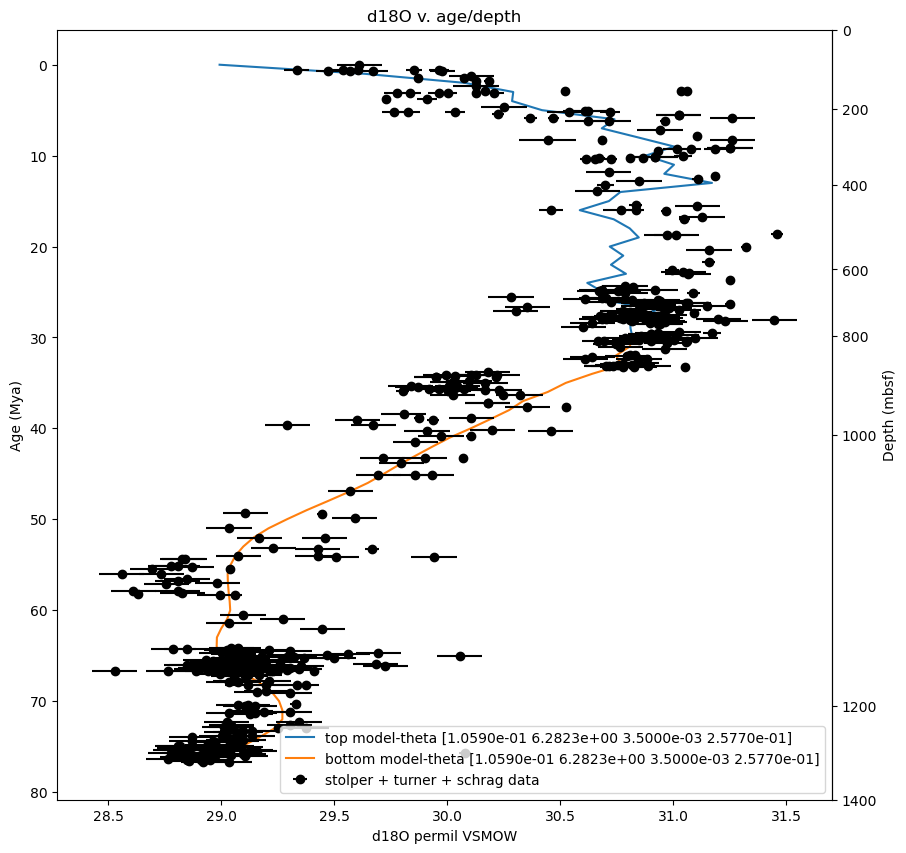

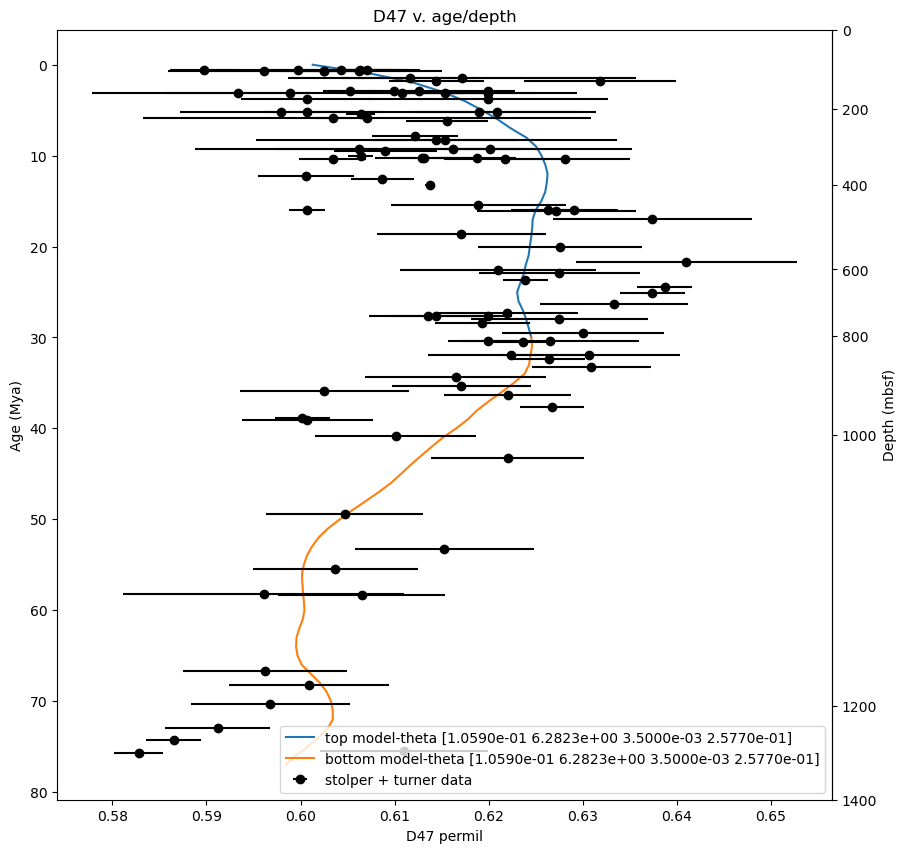

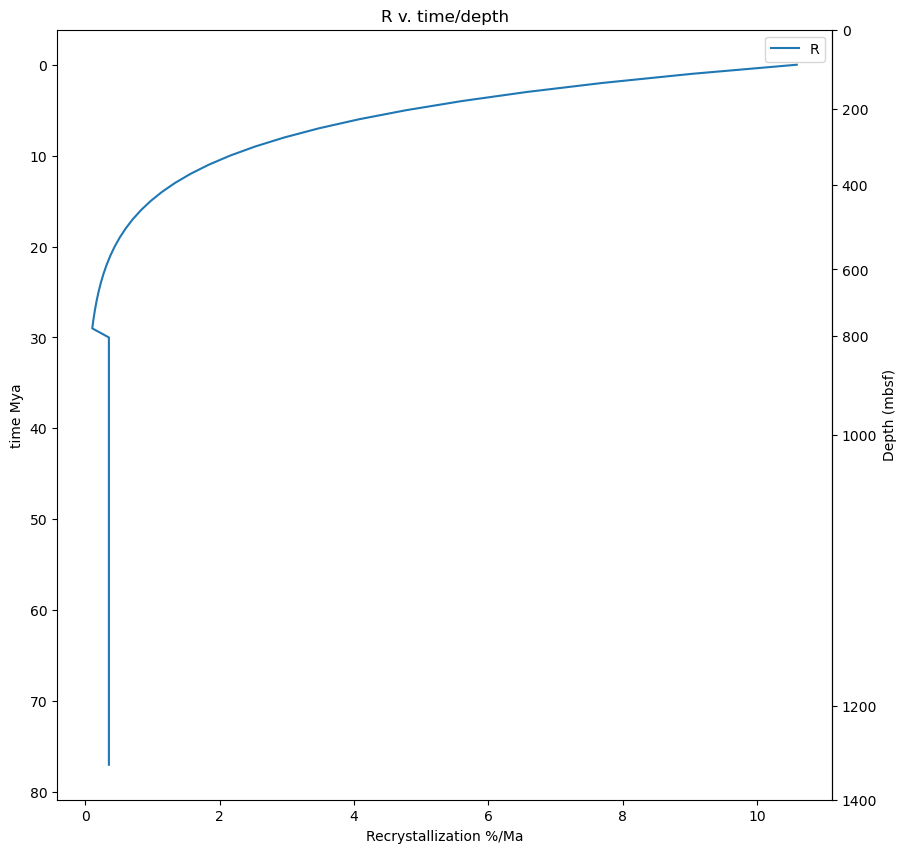

Integrated R top:  0.6598178490641693


In [11]:
theta_MLE_full = MLE_full_core(neg_log_likelihood_d18O_4data_mean, boundary_conditions_and_data, plot = True)
theta_MLE_full =  np.append(theta_MLE_full, np.random.rand(len(SST_basis[1])))

### MCMC Full core fit

The workflow for the full core fit is effectively the same as for the top core, just a few inputs are changed in some of the functions

>diag_MCMC(walkers, nsteps, burnin, log_prob_fn, boundary_conditions_and_data, MLE_estimate, path = './')

The `log_prob_fn` argument tell the function which probability function to use: 

`log_probability_d18O_4data`

The `path` argument tell the function where to save plots generated by the function. The two plots generated are a plot of the chains and a corner plot. The default path is the working directory folder, but here we will point the path to a specific folder for the full core.

100%|██████████| 2/2 [00:01<00:00,  1.51it/s]


Autocorrelation time: [90.40860886 94.29031882 85.28071857 94.63653088 77.98863199 75.45869205
 74.09472519 82.60364892 97.19984194 74.30186685 69.96048627 69.99269812
 77.08683618 79.86142619 80.56628373 81.56082218 79.55843864 70.83328646
 73.36441108]


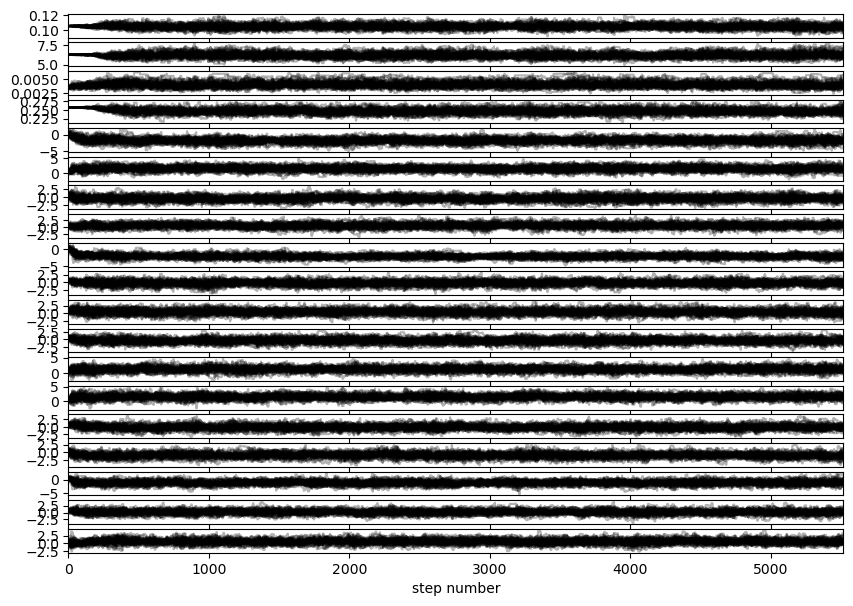

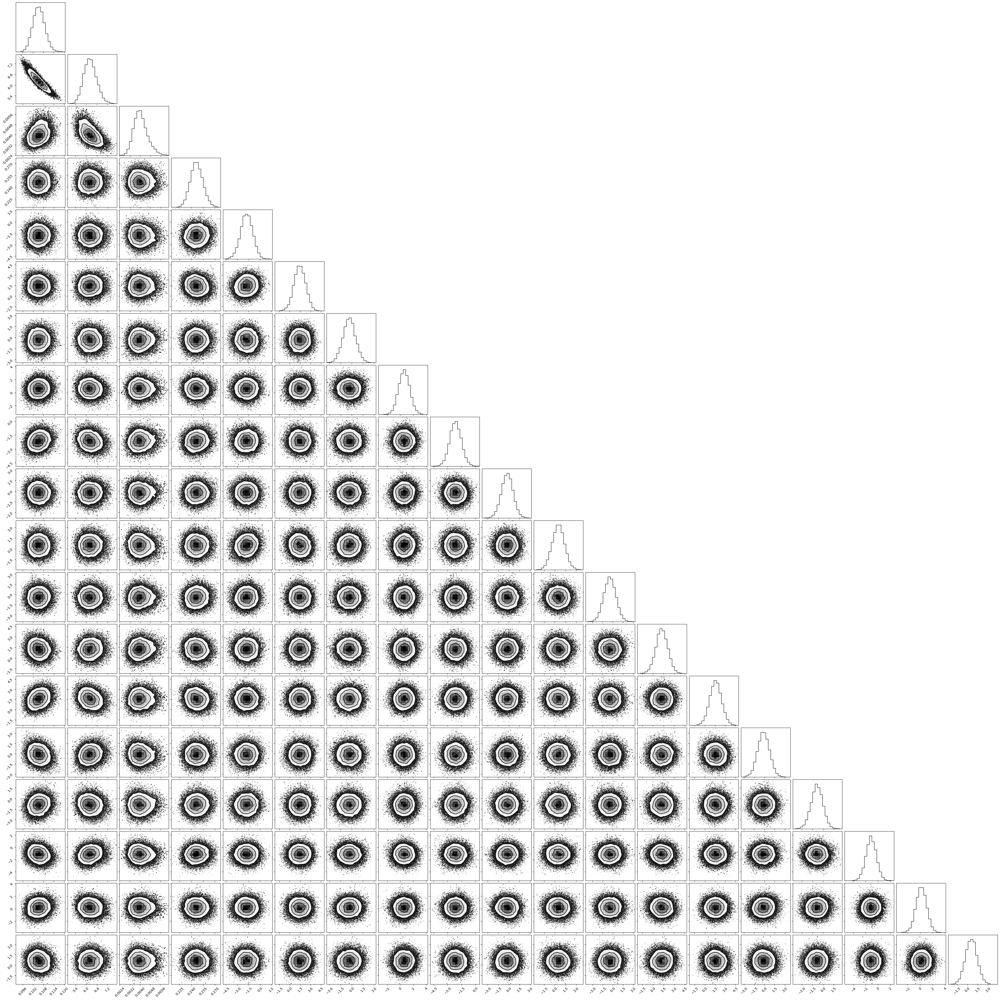

In [12]:
## With bootstraps in place, time to run the MCMC
walkers = 40
n_steps = 2
burnin = 400
MCMC_output_full = diag_MCMC(walkers, n_steps, burnin, log_probability_d18O_4data, boundary_conditions_and_data, theta_MLE_full, path = './d18O_full/', use_backend=True)


In [13]:
print('fit theta: \n', MCMC_output_full.params)

fit theta: 
 [ 1.05261654e-01  6.21154996e+00  3.99528023e-03  2.46409002e-01
 -1.78178668e+00  1.44790678e+00 -3.50379550e-01  5.94837104e-01
 -2.14787427e+00 -2.30455981e-01  4.85763342e-01 -4.40501814e-01
  1.25167813e+00  1.56879563e+00 -1.40352329e-01 -8.72812517e-01
 -1.11653248e+00  1.79290656e-01  5.77805076e-01]


In [14]:
MCMC_output_full.sampler.acceptance_fraction

array([0.21906142, 0.2056532 , 0.21362566, 0.20202935, 0.21000181,
       0.1917014 , 0.21652473, 0.21380685, 0.210183  , 0.21543758,
       0.21579996, 0.20366008, 0.20855227, 0.20492843, 0.21199493,
       0.20003624, 0.20547201, 0.19478166, 0.20601558, 0.20510962,
       0.21090777, 0.19514405, 0.20891466, 0.19333213, 0.20855227,
       0.21688712, 0.18391013, 0.19260736, 0.21869904, 0.2103642 ,
       0.20148578, 0.20818989, 0.20601558, 0.21561877, 0.20402247,
       0.19985505, 0.2080087 , 0.20148578, 0.20420366, 0.21163254])

The `diag_MCMC` class has the following instance variables:

>self.flat_samples

^The Markov chain with the burnin discarded

>self.params

^theta, The meadian paramter estimates

>self.tau

^The autocorrelation time


**Pay attention to the autocorrelation time `tau`!** The autocorrelation time tells you after how many steps do you forget where you are in the paramter space. You get the effective sample size by dividing $N_{steps}/\tau$ for a given parameter. Generally, you want $\tau < N_{steps}/50$, which would be an effective sample size of 50 or greater. 

In [17]:
print('tau: ', MCMC_output_full.tau)

tau:  [90.40860886 94.29031882 85.28071857 94.63653088 77.98863199 75.45869205
 74.09472519 82.60364892 97.19984194 74.30186685 69.96048627 69.99269812
 77.08683618 79.86142619 80.56628373 81.56082218 79.55843864 70.83328646
 73.36441108]


### Plotting uncertainty percentiles

The `percentiles` class is the same as above. 

The required arguments are `chain` and `tau`. The function will sample the chain at the "effective sample size" ($\tau/N_{steps}$), run the model for each sample, the plot the outputs as percentiles. It is important to input the flat samples from the `diag_MCMC` class as to not include the burnin. If you want to, you can add in any of the regression arguments to make the plots also overlay LOESS regression. The `full_core` argument tells the function whether or not you fit the the top or full core, and therefore what recrystallization model to use. The `path` argument tells the function where to save the plots. 

> percentiles(flat_samples,
        boundary_conditions_and_data,
        n_curves=500,
        full_core=True,
        seed=None,
        path="./",
        make_plots=True)

In [18]:
full_percentiles = percentiles(MCMC_output_full.flat_samples, boundary_conditions_and_data, full_core = True, path = './d18O_full/', fit_to='d18O')

# MLE and MCMC fitting $\Delta_{47}$

We can repeat the same analysis as above, but using the $\Delta_{47}$ data instead. 

### MLE Top core fit

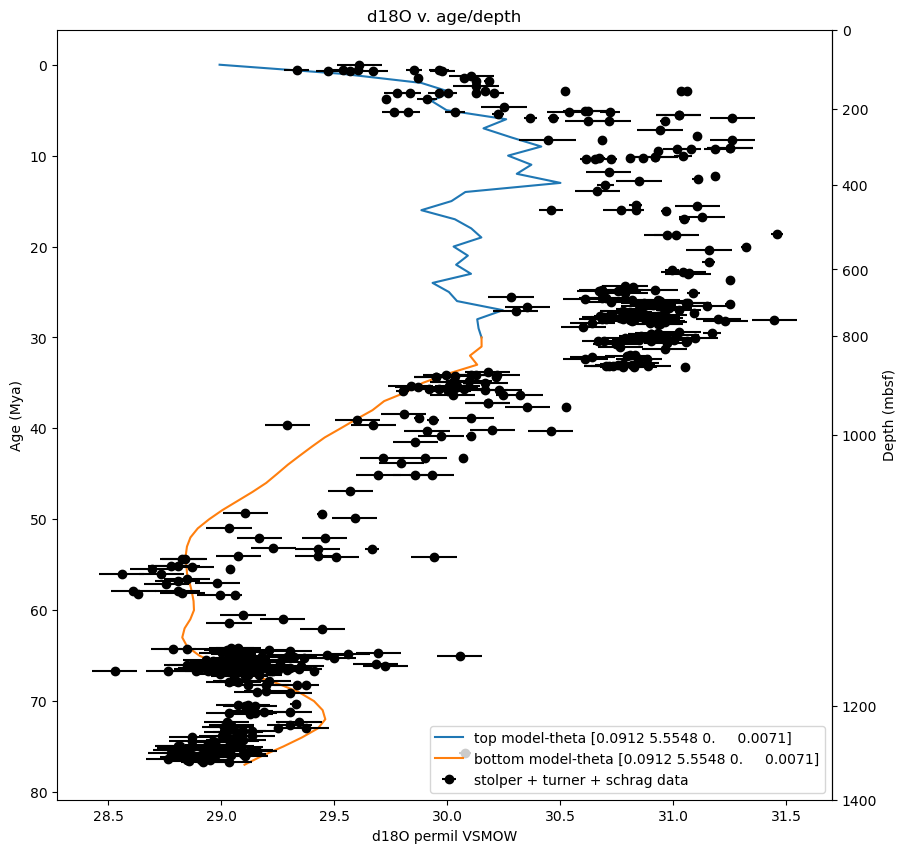

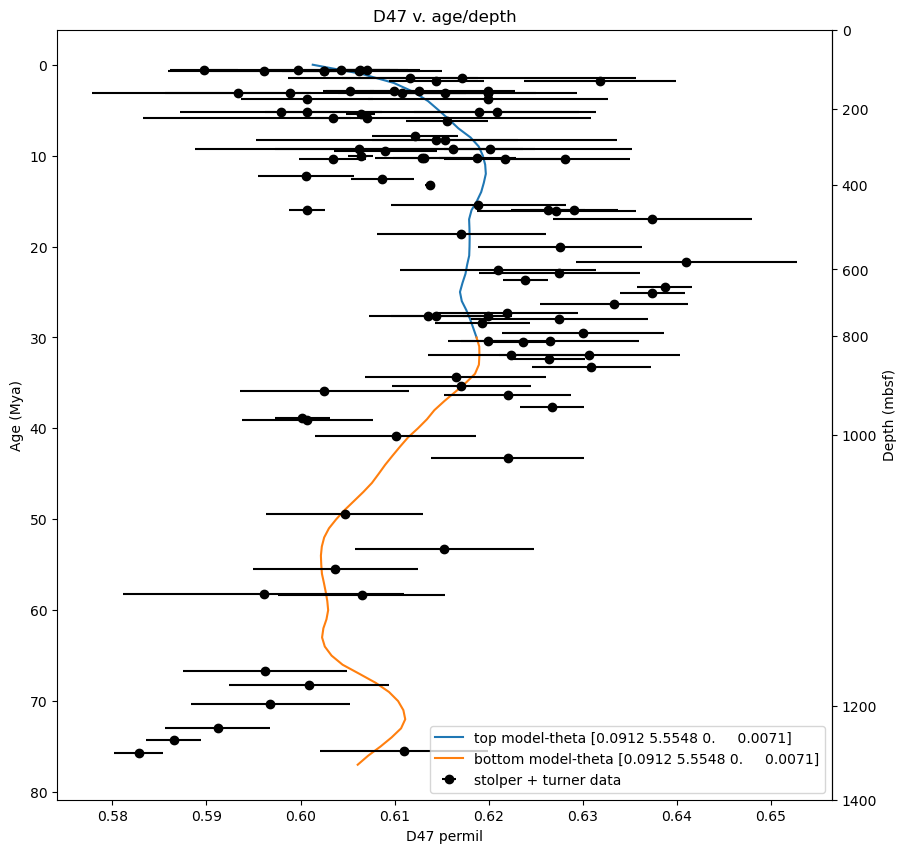

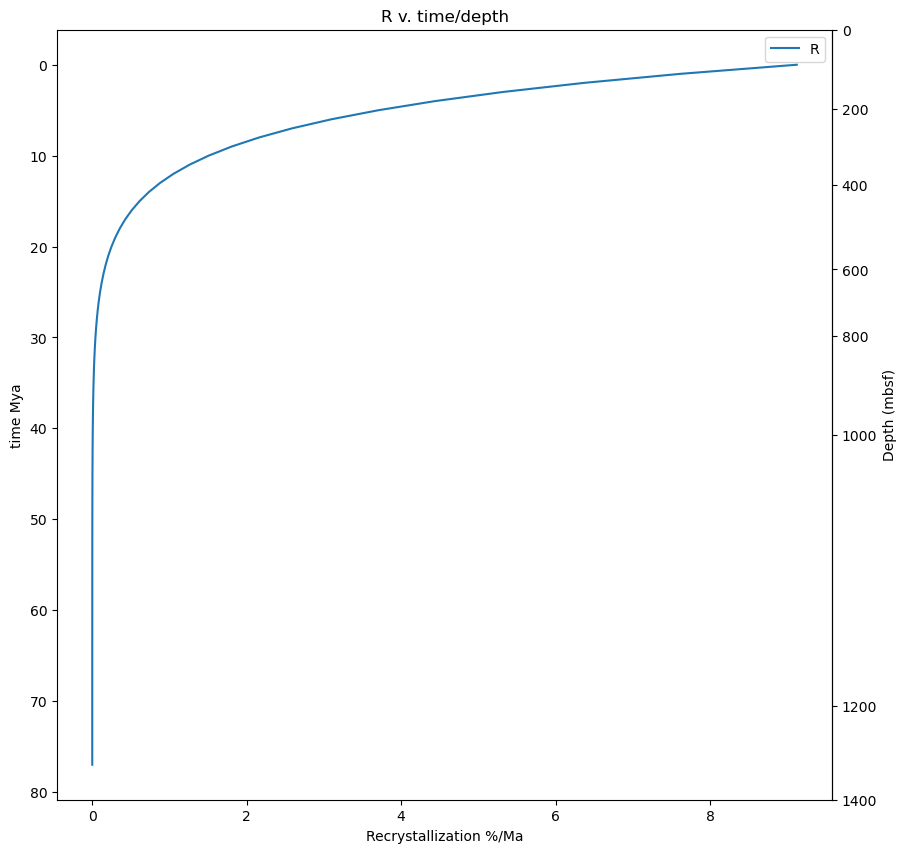

Integrated R top:  0.5044430030022844
theta_MLE =  [0.09122381 5.55479996 0.         0.00712696]
[beta, gamma, alpha,  s]


In [19]:
theta_MLE_top = MLE_top_core(neg_log_likelihood_D47_4top_4data_mean, boundary_conditions_and_data, plot=True)
print('theta_MLE = ', theta_MLE_top)
print('[beta, gamma, alpha,', " s]")
theta_MLE_top = np.append(theta_MLE_top, np.random.rand(len(SST_basis[1])))

### MCMC Top core fit

100%|██████████| 2/2 [00:00<00:00, 11.26it/s]


Autocorrelation time: [709.37823771 374.68805375 219.41681355 127.42617746 121.3104457
 119.74306934 119.56921313 129.93941506 135.90472828 129.05680324
 119.52798613 125.82359605 127.42711706 125.26276419 123.39316613
 130.91474806 124.00400746 132.11490676 115.47007465]


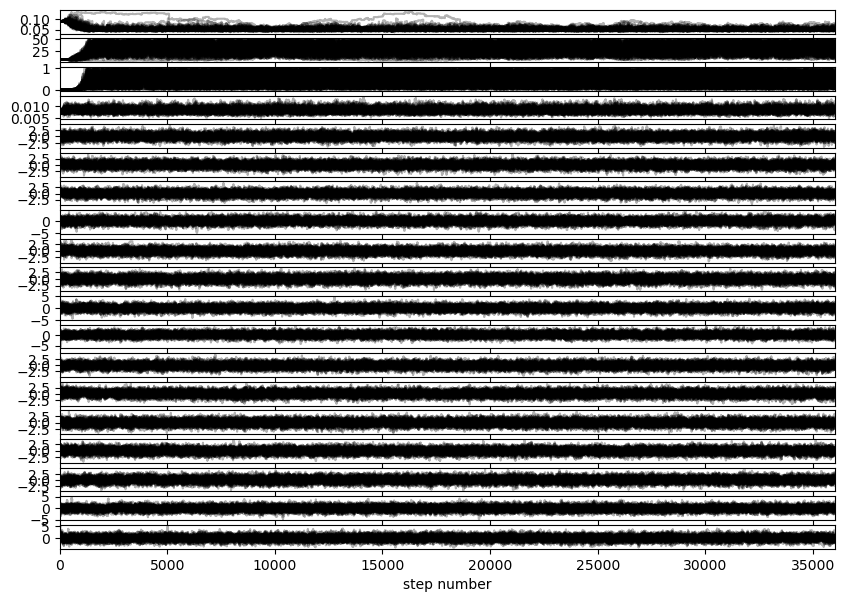

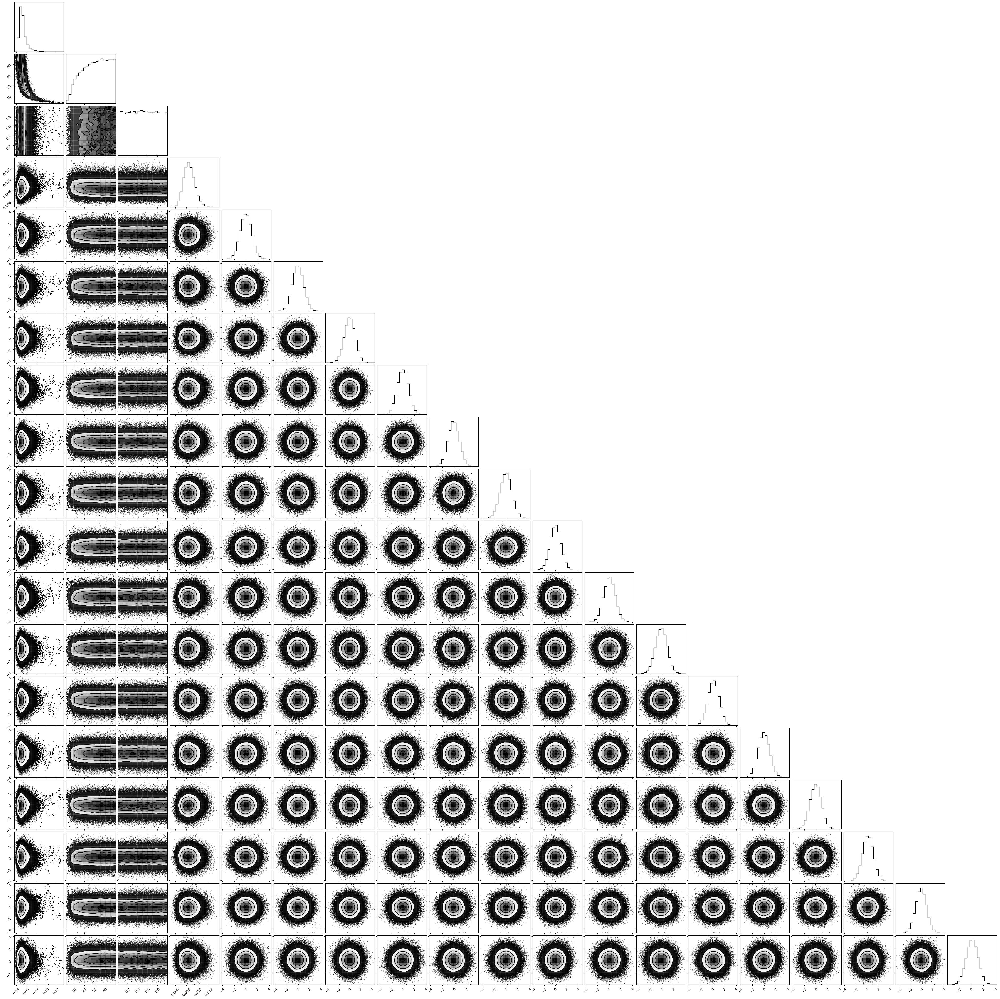

In [20]:
walkers = 40
n_steps = 2
burnin = 8000
MCMC_output_top = diag_MCMC(walkers, n_steps, burnin, log_probability_D47_4top_4data, boundary_conditions_and_data, theta_MLE_top, path = './D47_top/', use_backend=True)

In [23]:
print('fit theta: \n', MCMC_output_top.params)

fit theta: 
 [ 5.14304540e-02  3.11703311e+01  4.99466280e-01  8.42287754e-03
 -1.62730563e-02 -2.70784776e-02  7.39003060e-03 -9.89803674e-03
 -1.72374046e-01 -7.26715666e-03 -2.80125087e-03  4.96216483e-02
 -1.11996438e-01  1.65258711e-01 -4.90115233e-02 -9.94146655e-02
  1.26728214e-01 -1.31614496e-01  1.49008483e-01]


In [24]:
top_percentiles = percentiles(MCMC_output_top.flat_samples, boundary_conditions_and_data, full_core = False, path = './D47_top/', fit_to='D47')

### MLE Full core fit

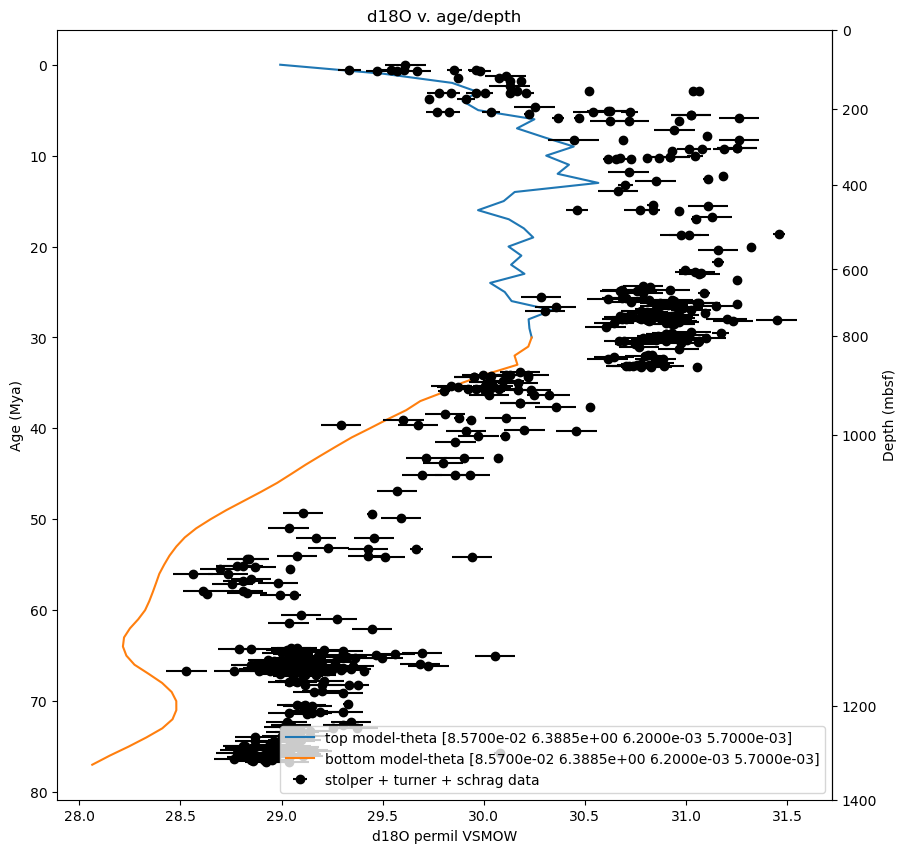

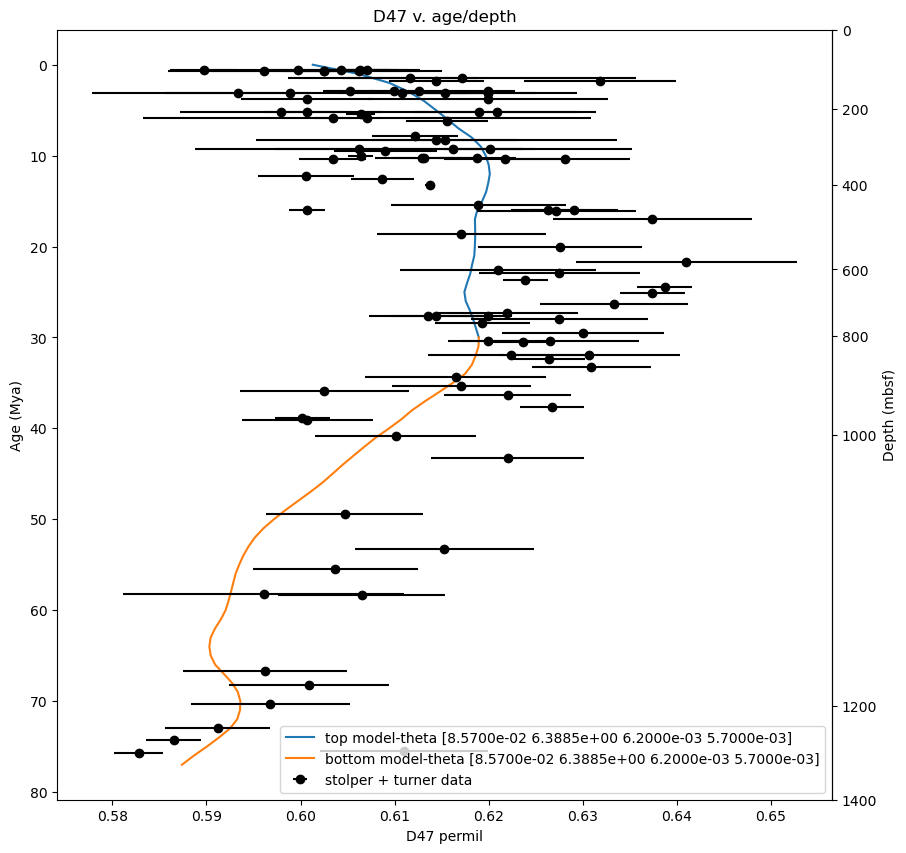

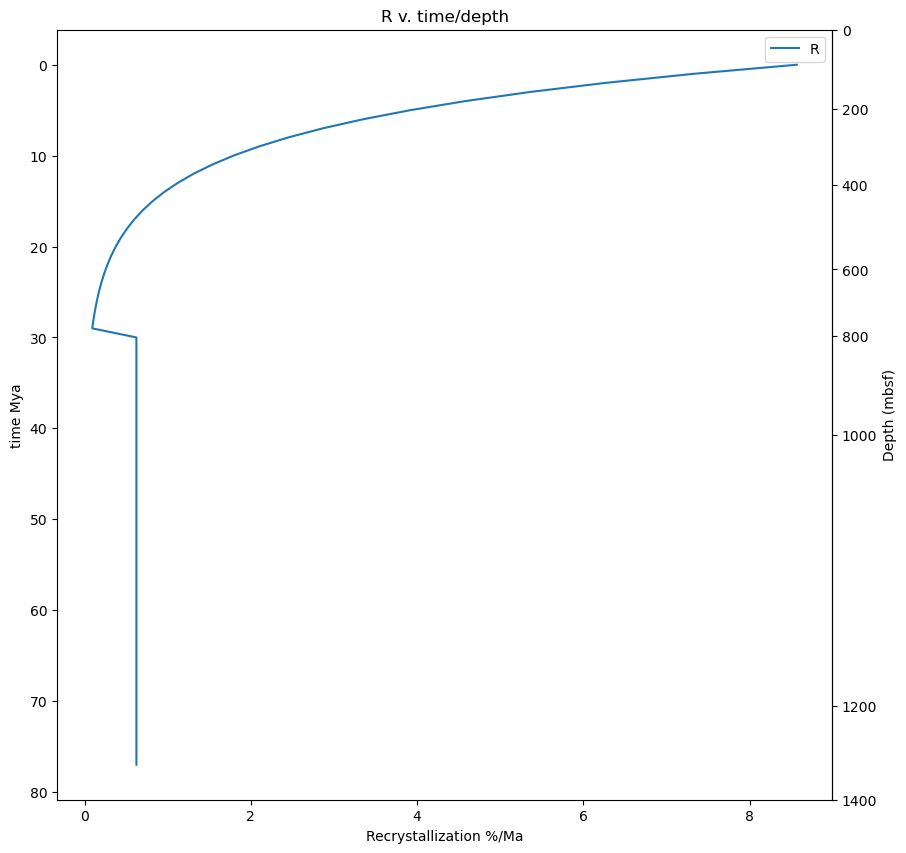

Integrated R top:  0.5422281902253085
theta_MLE =  [8.56584758e-02 6.38845662e+00 6.22770957e-03 5.69771469e-03]
[beta, gamma, alpha,  s]


In [25]:
theta_MLE_full = MLE_full_core(neg_log_likelihood_D47_4data_mean, boundary_conditions_and_data, plot=True)
print('theta_MLE = ', theta_MLE_full)
print('[beta, gamma, alpha,', " s]")
theta_MLE_full = np.append(theta_MLE_full, np.random.rand(len(SST_basis[1])))

### MCMC Full core fit

100%|██████████| 2/2 [00:00<00:00,  2.57it/s]


Autocorrelation time: [529.65243671 350.66682534 181.53263109 138.18256558 141.24239208
 132.55215508 145.24458953 131.93391381 129.71423763 136.76652972
 143.03970698 137.97894403 141.97146297 137.3246309  131.72538015
 138.5567707  142.19452449 149.05533585 134.57866023]


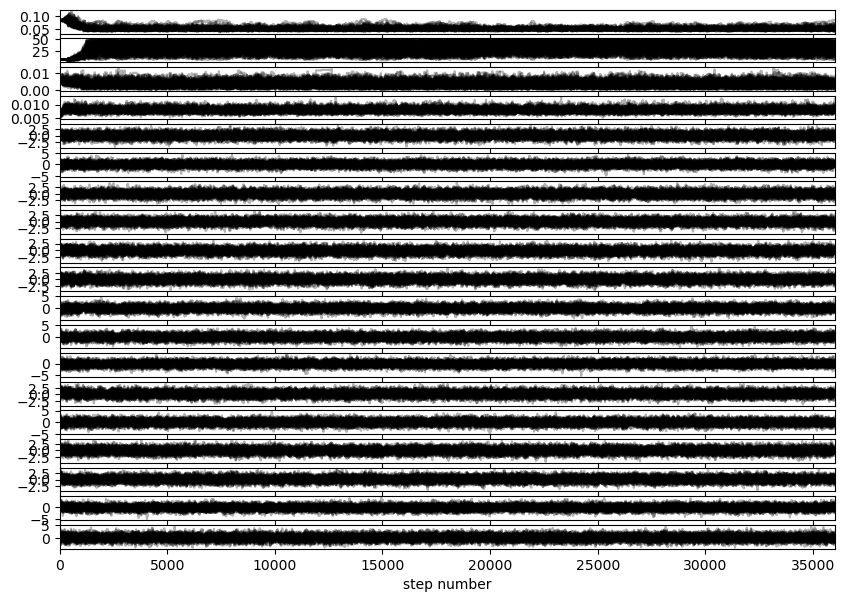

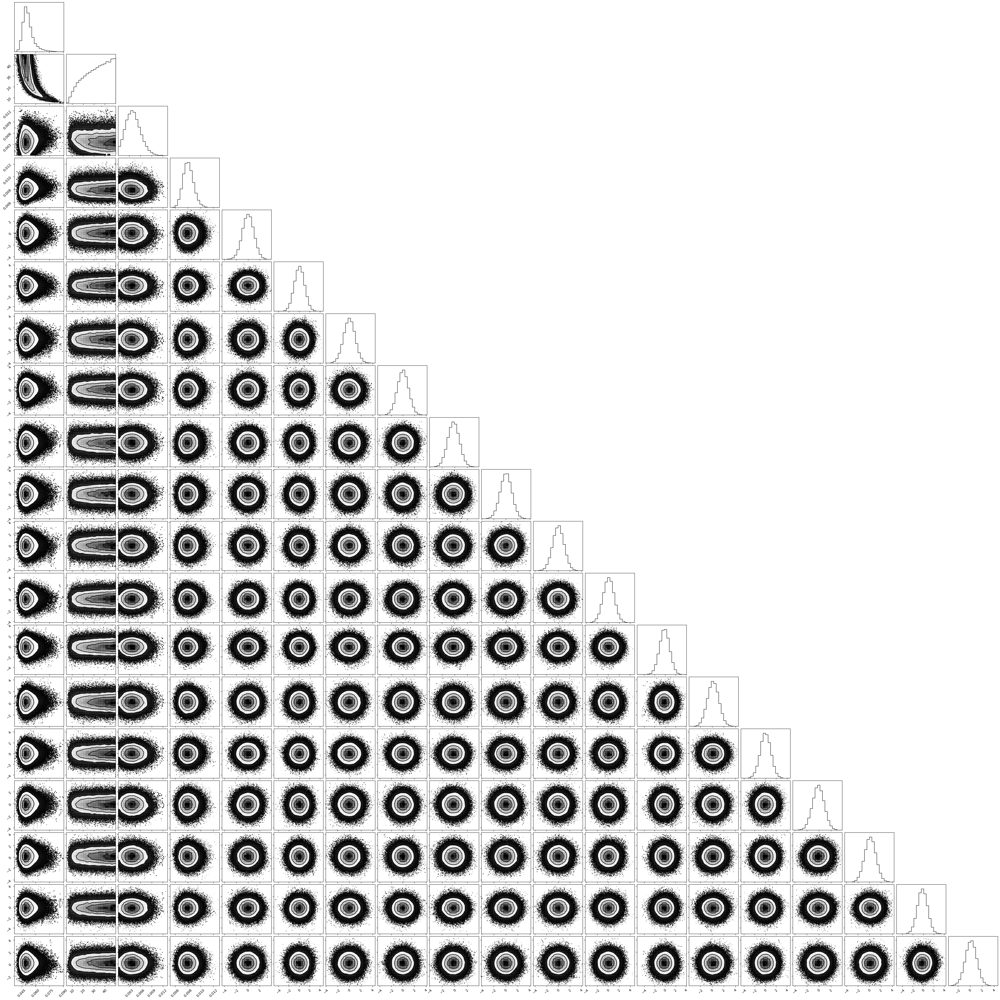

In [26]:
walkers = 40
n_steps = 2
burnin = 2000
MCMC_output_full = diag_MCMC(walkers, n_steps, burnin, log_probability_D47_4data, boundary_conditions_and_data, theta_MLE_full, path = './D47_full/', use_backend=True)

In [27]:
print('fit theta: \n', MCMC_output_full.params)

fit theta: 
 [ 5.08157568e-02  3.38149430e+01  3.90744526e-03  8.02375696e-03
  8.34489454e-03  1.88019431e-03 -1.29654970e-02 -1.50681988e-02
 -1.99536262e-01  1.88190258e-02  6.58988195e-03  7.77128605e-02
 -1.34116596e-01  1.74048822e-01 -2.20207874e-02 -1.02554439e-01
  1.40324620e-01 -1.89724151e-01  1.58910640e-01]


In [28]:
full_percentiles = percentiles(MCMC_output_full.flat_samples, boundary_conditions_and_data, full_core = True, path = './D47_full/', fit_to='D47')